# Capstone: Define and Solve an ML Problem

In [1]:
import pandas as pd
import numpy as np
import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time

**Note**: As you work through the notebook, you can import additional packages as needed.

## Overview


In this capstone assignment, you will follow the machine learning life cycle and implement one of the supervised learning models you have learned so far in this course, along with a neural network, to solve a predictive problem.

This capstone spans two lab sessions.

- **Unit 5 Lab:** You will define a machine learning problem, explore and prepare your data, and train, test, evaluate and improve a traditional machine learning model (Parts 1–5).
- **Unit 6 Lab:** After completing Unit 6 on neural networks, you will apply a neural network to the same problem and compare the two approaches (Parts 6–7).

There is a checkpoint at the end of Part 5 that marks where to stop during the Unit 5 lab.

You will complete the following:

1. Choose your Data Set and Build Your DataFrame
2. Define Your ML Problem
3. Understand Your Data
4. Prepare Your Data
5. Train, Test, Evaluate and Improve a Traditional Machine Learning Model *(Unit 5 lab)*
6. Train, Test, Evaluate and Improve Neural Network *(Unit 6 lab)*
7. Compare Your Models and Reflect *(Unit 6 lab)*

**This is an individual assignment.** You are welcome to discuss ideas with your peers, but the code and written responses you submit must be your own.

**Note:** This capstone is intentionally less scaffolded than your weekly labs; that is by design. You are expected to make your own implementation choices, add code cells as needed, and document your reasoning throughout.

## Part 1: Choose Your Data Set and Build Your DataFrame


You will choose one of two data sets to work with for this capstone. In both cases, you will be solving a supervised learning binary classification problem by predicting one of two possible class labels. Both data sets have been used earlier in the course, so you are already familiar with their structure. 

**Option A: Census Income Data** (`censusData.csv`)
This data set contains demographic and employment information from the 1994 U.S. Census. You will use it to predict whether an individual's annual income exceeds $50,000. Your label column is `income_binary`, which contains two values: `<=50K` and `>50K`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Option B: Airbnb NYC Listings Data** (`airbnbListingsData.csv`)
This data set contains information about Airbnb listings in New York City. You will use it to predict whether a listing is high-priced. The data set includes a new `price_category` column that classifies each listing as either "high price" or "low price" based on whether the listing’s price falls above or below the 75th percentile of all listing prices. Listings at or above the 75th percentile are labeled as `high`, while the remaining listings are labeled as `low`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Note:**  These versions of the data sets differ slightly from the versions you have worked with in this program. For example, they may not include some of the preprocessing necessary for specific models. 

#### Load a Data Set and Save it as a Pandas DataFrame

The code cell below contains filenames (path + filename) for the two data sets available to you.

<b>Task:</b> In the code cell below, load your chosen data set using `pd.read_csv()` and save it to a DataFrame named `df`. Then call `df.head()` to inspect the first few row of the data set.

In [2]:
# File paths for both data sets
census_filename = os.path.join(os.getcwd(), "data_capstone", "censusData.csv")
airbnb_filename = os.path.join(os.getcwd(), "data_capstone", "airbnbListingsData.csv")

# Load your chosen dataset and save it to df
df = pd.read_csv(airbnb_filename)

df.head(10)

                                                name  \
0                              Skylit Midtown Castle   
1  Whole flr w/private bdrm, bath & kitchen(pls r...   
2           Spacious Brooklyn Duplex, Patio + Garden   
3                   Large Furnished Room Near B'way　   
4                 Cozy Clean Guest Room - Family Apt   
5     Lovely Room 1, Garden, Best Area, Legal rental   
6                   Only 2 stops to Manhattan studio   
7                            UES Beautiful Blue Room   
8  Amazing location! Wburg. Large, bright & tranquil   
9        Perfect for Your Parents:  Privacy + Garden   

                                         description  \
0  Beautiful, spacious skylit studio in the heart...   
1  Enjoy 500 s.f. top floor in 1899 brownstone, w...   
2  We welcome you to stay in our lovely 2 br dupl...   
3  Please don’t expect the luxury here just a bas...   
4  Our best guests are seeking a safe, clean, spa...   
5  Beautiful house, gorgeous garden, patio, coz

## Part 2: Define Your ML Problem

The first step of the machine learning life cycle involves defining your business problem. In the markdown cell below, you will clearly define what you are trying to predict and why it matters. 

<b>Task</b>: In the markdown cell below, answer all of the following questions:

1. Which data set did you choose?
2. What is your label? What are you predicting?
3. What features do you plan to use? (This list may change after you explore your data.)
5. Why does this problem matter? Using the business brief you read in the lab overview page, explain how the organization described there could use a model that predicts this label to create value or inform decisions for their client.

1. I chose the Airbnb dataset.

2. My label is 'price_category' because the business problem wants to predict whether an Airbnb listing is high-priced, ultimately to automate the classification of listings into pricing tiers as per the client's request.

3. Some of the features I plan to use are 'review_scores_rating', 'bathrooms', 'bedrooms', 'beds', and 'host_location'; however, this is highly likely to change after feature engineering. 

4. This problem matters because the client is a hospitality investment group that wishes to provide a categorized listing for their premium portfolio. By making the classification process efficient through fast calculations that would evaluate of many features and the correlations amongst them, the client can create a more accurate and consistent portfolio.

## Part 3: Understand Your Data

Now that you have defined your problem, perform exploratory data analysis (EDA) with that problem in mind. Consider the following as you inspect your data:

1. What data preparation techniques would you like to use? These data preparation techniques may include:

    * handling missing values
    * finding and replacing outliers
    * performing feature engineering techniques such as one-hot encoding on categorical features
    * selecting appropriate features and removing irrelevant features
    * addressing class imbalance


2. What machine learning model would you like to use that is suitable for your predictive problem and data?
   * You may use one of the following models that you have worked with so far:
        - K-Nearest Neighbors (KNN)
        - Decision Tree
        - Logistic Regression
   * Are there other data preparation techniques that you will need to apply to build a balanced modeling data set for your problem and model? For example, will you need to scale your data?
 

3. How will you evaluate and improve the model's performance?
    * Are there specific evaluation metrics or methods that are appropriate for your problem, dataset, or selected model?
    
<b>Task</b>: In the code cells below, use the techniques you have learned in this course to inspect and analyze your data.

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [3]:
# CHECKING NULL VALUES 
nan_count = np.sum(df.isnull(), axis = 0)
print(nan_count)

nan_condition = nan_count != 0 # look for all columns with missing values

nan_col_names = nan_count[nan_condition].index # get the column names
print(nan_col_names)

nan_cols = list(nan_col_names) # convert column names to list
print(nan_cols)

nan_col_types = df[nan_cols].dtypes
print(nan_col_types)

# Features of concern: description, neighborhood_overview, host_about, host_response_rate, host_acceptance_rate, bedrooms, beds
# Non-numerical features: description, neighborhood_overview, host_about

name                                                5
description                                       570
neighborhood_overview                            9816
host_name                                           0
host_location                                      60
host_about                                      10945
host_response_rate                              11843
host_acceptance_rate                            11113
host_is_superhost                                   0
host_listings_count                                 0
host_total_listings_count                           0
host_has_profile_pic                                0
host_identity_verified                              0
neighbourhood_group_cleansed                        0
room_type                                           0
accommodates                                        0
bathrooms                                           0
bedrooms                                         2918
beds                        

In [4]:
# CHECKING FEATURES THAT CAN BE CATEGORIZED (ONE-HOT-ENCODING)
unique_count = df.nunique()
print(unique_count)

# Likely features: price_category(2), neighbourhood_group_cleansed(5), room_type(4), instant_bookable(2), has_availability(2)

name                                            27386
description                                     25952
neighborhood_overview                           15800
host_name                                        7566
host_location                                    1364
host_about                                      11962
host_response_rate                                 85
host_acceptance_rate                              101
host_is_superhost                                   1
host_listings_count                                73
host_total_listings_count                          73
host_has_profile_pic                                1
host_identity_verified                              1
neighbourhood_group_cleansed                        5
room_type                                           4
accommodates                                       16
bathrooms                                          16
bedrooms                                           11
beds                        

### Class Imbalance

Examine the distribution of your label column to determine whether class imbalance is present. Use at least one visualization to show the class distribution. In the **EDA Summary** below, you will discuss how you plan to address any observed imbalance during data preparation.

In [5]:
# YOUR CODE HERE
df['price'].describe()

count    28022.000000
mean       154.228749
std        140.816605
min         29.000000
25%         70.000000
50%        115.000000
75%        180.000000
max       1000.000000
Name: price, dtype: float64

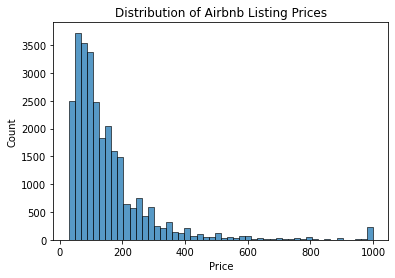

In [6]:
sns.histplot(df['price'], bins=50)

plt.title('Distribution of Airbnb Listing Prices')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

In [7]:
df['price_category'].describe()

count     28022
unique        2
top         low
freq      20785
Name: price_category, dtype: object

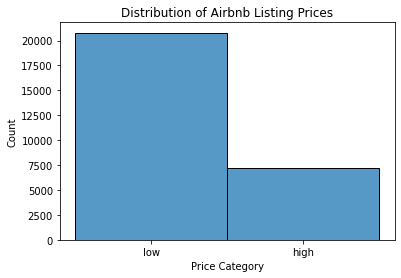

In [8]:
sns.histplot(df['price_category'], bins=50)

plt.title('Distribution of Airbnb Listing Prices')
plt.xlabel('Price Category')
plt.ylabel('Count')
plt.show()

### Inspect and Analyze Your Data

Explore your features. Use summary statistics and visualizations to understand how your features are distributed and how they relate to the label. Identify issues such as missing values, outliers, or a feature that is irrelevant or redundant.

Think of the different techniques you have used to inspect and analyze your data in this course. These include using Pandas to apply data filters, using the Pandas `describe()` method to get insight into key statistics for each column, using the Pandas `dtypes` property to inspect the data type of each column, and using Matplotlib and Seaborn to detect outliers and visualize relationships between features and labels. 

Use at least one plot that visualizes a relationship between features and the label.

In [9]:
# YOUR CODE HERE
df.describe()

,host_response_rate,host_acceptance_rate,host_listings_count,host_total_listings_count,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,n_host_verifications
count,16179.000000,16909.000000,28022.000000,28022.000000,28022.000000,28022.000000,25104.000000,26668.000000,28022.000000,28022.000000,...,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000,28022.000000
mean,0.906901,0.791953,14.554778,14.554778,2.874491,1.142174,1.329708,1.629556,154.228749,18.689387,...,4.814300,4.808041,4.750393,4.647670,9.581900,5.562986,3.902077,0.048283,1.758325,5.169510
std,0.227282,0.276732,120.721287,120.721287,1.860251,0.421132,0.700726,1.097104,140.816605,25.569151,...,0.438603,0.464585,0.415717,0.518023,32.227523,26.121426,17.972386,0.442459,4.446143,2.028497
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,29.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000,1.000000
25%,0.940000,0.680000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,70.000000,2.000000,...,4.810000,4.810000,4.670000,4.550000,1.000000,0.000000,0.000000,0.000000,0.130000,4.000000
50%,1.000000,0.910000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,115.000000,30.000000,...,4.960000,4.970000,4.880000,4.780000,1.000000,1.000000,0.000000,0.000000,0.510000,5.000000
75%,1.000000,1.000000,3.000000,3.000000,4.000000,1.000000,1.000000,2.000000,180.000000,30.000000,...,5.000000,5.000000,5.000000,5.000000,3.000000,1.000000,1.000000,0.000000,1.830000,7.000000
max,1.000000,1.000000,3387.000000,3387.000000,16.000000,8.000000,12.000000,21.000000,1000.000000,1250.000000,...,5.000000,5.000000,5.000000,5.000000,421.000000,308.000000,359.000000,8.000000,141.000000,13.000000


In [10]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])
corr_with_price = numeric_df.corr()['price'].sort_values(key=abs, ascending=False)

print(corr_with_price.head(10))

price                     1.000000
accommodates              0.519057
bedrooms                  0.475506
beds                      0.409236
bathrooms                 0.331297
availability_60           0.152750
availability_90           0.148228
availability_30           0.146895
availability_365          0.123984
maximum_maximum_nights    0.107901
Name: price, dtype: float64


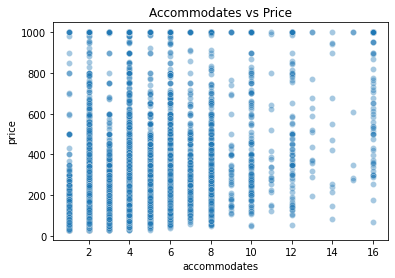

In [11]:
sns.scatterplot(
    data=df,
    x='accommodates',
    y='price',
    alpha=0.4
)

plt.title('Accommodates vs Price')
plt.show()

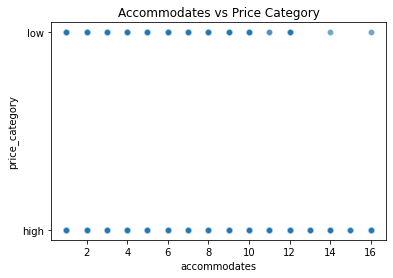

In [12]:
sns.scatterplot(
    data=df,
    x='accommodates',
    y='price_category',
    alpha=0.4
)

plt.title('Accommodates vs Price Category')
plt.show()

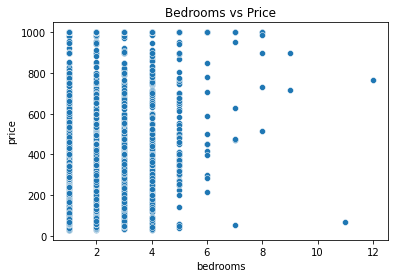

In [13]:
sns.scatterplot(
    data=df,
    x='bedrooms',
    y='price'
)

plt.title('Bedrooms vs Price')
plt.show()

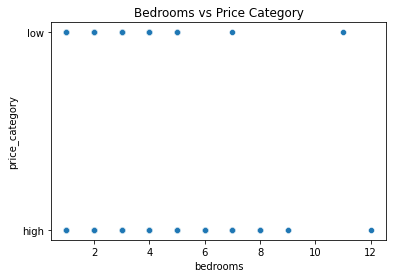

In [14]:
sns.scatterplot(
    data=df,
    x='bedrooms',
    y='price_category'
)

plt.title('Bedrooms vs Price Category')
plt.show()

### EDA Summary

<b>Task</b>: In the markdown cell below, summarize the key findings from your data exploration. Describe any patterns, anomalies, or data quality issues you identified and explain how those findings may influence your data preparation decisions. For example, your exploration may affect how you handle missing values, address class imbalance, or determine which features to keep or remove.

During exploratory data analysis, I examined the distribution of the price variable and found that it is heavily right-skewed, with most Airbnb listings concentrated at lower price ranges and a small number of extremely expensive listings. These high-priced listings appear to be potential outliers that may disproportionately influence model training and evaluation. To address this issue, I may apply outlier treatment techniques such as winsorization.

I also inspected feature distributions, data types, and missing values to identify potential data quality issues: 
- Numerical features such as bedrooms, bathrooms, and beds showed varying ranges and may require further investigation for unrealistic values
- Categorical features such as price_category, neighbourhood_group_cleansed, room_type, instant_bookable, and has_availability will require one-hot encoding before modeling
- Non-numerical features with a significant amount of missing values, such as description, neighborhood_overview, and host_about, will probably be dropped
- Numerical features with missing values will probably be replaced with the mean.

### Ethical Considerations:

Machine learning models can cause harm when they reflect or amplify biases in the data they are trained on. 

<b>Task</b>: In the markdown cell below, answer both of the following questions:

1. What biases or ethical concerns might be present in your dataset? Think about who collected the data, how it was collected, and which groups of people appear in it. Are there features in the dataset that could serve as proxies for protected characteristics like race, gender, or socioeconomic status?
2. Who could be harmed by a model that makes incorrect predictions on this data, and how? Be specific about which groups are most at risk and what the real-world consequences of errors might look like.

One potential bias in the Airbnb NYC dataset comes from location-based features such as neighborhood, borough, and host location. These features may be related to differences in income levels and housing values across New York City, which means the model could learn patterns that reflect existing economic inequalities. The dataset also only includes Airbnb listings, so it may not represent all types of rental properties or hosts.

Hosts and property owners could be harmed if the model makes incorrect predictions. If a listing is predicted to be low-priced when it is actually high-priced, it may be overlooked for investment or marketing opportunities. On the other hand, if a listing is predicted to be high-priced when it is not, resources may be wasted on that property. Certain neighborhoods could also be affected if the model consistently favors or undervalues listings in particular areas, leading to unfair outcomes for some hosts.

## Part 4: Prepare Your Data

<b>Task</b>: In the code cell below, prepare your data for modeling. The specific steps you take will depend on what you found during your EDA and which model you plan to use. 

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [15]:
# YOUR CODE HERE

# Dropping features that have heavy text blocks, or significant missing values and can't be replaced
df = df.drop(columns = ['neighborhood_overview', 'description', 'neighborhood_overview', 'host_about'])

# Creating dummy variables for missing data
mean_response_rate=df['host_response_rate'].mean()
mean_acceptance_rate=df['host_acceptance_rate'].mean()
mean_bedrooms=df['bedrooms'].mean()
mean_beds=df['beds'].mean()

df['host_response_rate'].fillna(value=mean_response_rate, inplace=True)
df['host_acceptance_rate'].fillna(value=mean_acceptance_rate, inplace=True)
df['bedrooms'].fillna(value=mean_bedrooms, inplace=True)
df['beds'].fillna(value=mean_beds, inplace=True)

# One-hot encoding categorical values
# Likely features: neighbourhood_group_cleansed(5), room_type(4), instant_bookable(2), has_availability(2)
df_neighbourhood_group_cleansed = pd.get_dummies(df['neighbourhood_group_cleansed'], prefix='neighbourhood_group_cleansed')
df_room_type = pd.get_dummies(df['room_type'], prefix='room_type_')
df_instant_bookable = pd.get_dummies(df['instant_bookable'], prefix='instant_bookable_')
df_has_availability = pd.get_dummies(df['has_availability'], prefix='has_availability_')

df = df.join([df_neighbourhood_group_cleansed,df_room_type,df_instant_bookable,df_has_availability])
df.drop(columns = ['neighbourhood_group_cleansed','room_type','instant_bookable','has_availability'], inplace=True)


In [16]:
df.head()

,name,host_name,host_location,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_total_listings_count,host_has_profile_pic,host_identity_verified,...,neighbourhood_group_cleansed_Queens,neighbourhood_group_cleansed_Staten Island,room_type__Entire home/apt,room_type__Hotel room,room_type__Private room,room_type__Shared room,instant_bookable__False,instant_bookable__True,has_availability__False,has_availability__True
0,Skylit Midtown Castle,Jennifer,"New York, New York, United States",0.800000,0.170000,True,8.0,8.0,True,True,...,0,0,1,0,0,0,1,0,0,1
1,"Whole flr w/private bdrm, bath & kitchen(pls r...",LisaRoxanne,"New York, New York, United States",0.090000,0.690000,True,1.0,1.0,True,True,...,0,0,1,0,0,0,1,0,0,1
2,"Spacious Brooklyn Duplex, Patio + Garden",Rebecca,"Brooklyn, New York, United States",1.000000,0.250000,True,1.0,1.0,True,True,...,0,0,1,0,0,0,1,0,0,1
3,Large Furnished Room Near B'way,Shunichi,"New York, New York, United States",1.000000,1.000000,True,1.0,1.0,True,True,...,0,0,0,0,1,0,1,0,0,1
4,Cozy Clean Guest Room - Family Apt,MaryEllen,"New York, New York, United States",0.906901,0.791953,True,1.0,1.0,True,True,...,0,0,0,0,1,0,1,0,0,1


In [17]:
new_numeric_df = df.select_dtypes(include=['int64', 'float64'])
new_corr_with_price = numeric_df.corr()['price'].sort_values(key=abs, ascending=False)

print(new_corr_with_price.head(60))

price                                           1.000000
accommodates                                    0.519057
bedrooms                                        0.475506
beds                                            0.409236
bathrooms                                       0.331297
availability_60                                 0.152750
availability_90                                 0.148228
availability_30                                 0.146895
availability_365                                0.123984
maximum_maximum_nights                          0.107901
review_scores_location                          0.096610
maximum_nights_avg_ntm                          0.081589
review_scores_cleanliness                       0.081402
host_listings_count                             0.080995
host_total_listings_count                       0.080995
minimum_nights                                 -0.079945
minimum_minimum_nights                         -0.071261
minimum_maximum_nights         

### Data Preparation Summary:

<b>Task</b>: In the markdown cell below, document the data preparation steps you took. For each decision, explain why you made it. For example, why did you handle missing values the way you did? Why did you keep or remove certain features? If a preparation step depends on the model you selected (for example, scaling for KNN but not for a decision tree), explain that as well.

First, I removed the features neighborhood_overview, description, and host_about because they contained large amounts of text and significant missing values. These features would require additional natural language processing techniques and were not necessary for the classification models being considered.

Next, I handled missing values in host_response_rate, host_acceptance_rate, bedrooms, and beds by replacing missing entries with the mean value of each feature. Mean imputation allowed me to retain listings that would otherwise be removed while ensuring that the dataset contained no missing values for these important predictors.

I then applied one-hot encoding to the categorical features neighbourhood_group_cleansed, room_type, instant_bookable, and has_availability. Machine learning models such as Logistic Regression, Decision Trees, and KNN require numerical inputs, so converting categorical values into binary indicator variables allowed these features to be used during training. After creating the dummy variables, the original categorical columns were removed to avoid redundancy.

## Part 5: Train, Test, Evaluate, and Improve a Traditional Machine Learning Model

Now you will train, test and evaluate your model. You will also use model selection techniques to improve your model's performance by identifying the optimal hyperparameter configuration.

<b>Task</b>: In the code cells below, do the following:

1. Create labeled examples from the dataset
2. Create training and test sets out of the labeled examples 
3. Train, test and evaluate your model 
    * You must evaluate your model using accuracy and F1 score. Use `accuracy_score` and `f1_score` from `sklearn.metrics`. For the F1 score, use `average='binary'` since this is a binary classification problem. You will compare your model's performance to that of a neural network later in this capstone. Save the results of your evaluation metrics to variables for later comparison.
    * You may use additional evaluation metrics of your choosing.
4. Perform model selection through grid search cross-validation to identify optimal hyperparameter values for your model
5. Train, test and evaluate a final version of your model using the optimal hyperparameter configuration.
6. Interpret your model's outputs in the context of the business problem. Depending on the model you chose, this might mean:
    * KNN: Describe what your model's performance metrics tell you about its behavior. For example: How does accuracy change as you vary k? What does that suggest about the structure of your data?
    * Decision Tree: print or plot feature importances.
    * Logistic Regression: print or plot the model coefficients.



<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [18]:
# Create labeled examples from the dataset
# YOUR CODE HERE
print(df.dtypes)
feature_list = list(df.select_dtypes(exclude=['object', 'bool']).columns)

y = df['price_category']
X = df[feature_list].drop(columns='price')

name                                             object
host_name                                        object
host_location                                    object
host_response_rate                              float64
host_acceptance_rate                            float64
host_is_superhost                                  bool
host_listings_count                             float64
host_total_listings_count                       float64
host_has_profile_pic                               bool
host_identity_verified                             bool
accommodates                                      int64
bathrooms                                       float64
bedrooms                                        float64
beds                                            float64
amenities                                        object
price                                           float64
minimum_nights                                    int64
maximum_nights                                  

In [19]:
# Create training and test sets out of the labeled examples 
# YOUR CODE HERE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=123)
y_train.unique()
y_train = (y_train == 'high').astype(int)
y_test = (y_test == 'high').astype(int)
print(y_train.unique())


[1 0]


In [20]:
# Train, test and evaluate your model
# YOUR CODE HERE
def train_test_LR(X_train, y_train, X_test, y_test, c=1):
    model = LogisticRegression(C=c, max_iter=10000)

    model.fit(X_train, y_train)
    
    probability_predictions = model.predict_proba(X_test)
    
    l_loss = log_loss(y_test, probability_predictions)
    
    class_label_predictions = model.predict(X_test)
    
    acc_score = accuracy_score(y_test, class_label_predictions)
    
    return l_loss, acc_score

loss, acc = train_test_LR(X_train, y_train, X_test, y_test)
print('Log loss: ' + str(loss))
print('Accuracy: ' + str(acc))

Log loss: 0.618971390260767
Accuracy: 0.7447015570934256


/usr/local/lib/python3.6/dist-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)


In [21]:
def train_test_DT(X_train, X_test, y_train, y_test, depth, leaf=1, crit='entropy'):
    model_dt = DecisionTreeClassifier(criterion = crit, max_depth = depth, min_samples_leaf = leaf)
    model_dt.fit(X_train, y_train)
    class_label_predictions_dt = model_dt.predict(X_test)
    acc_score_dt = accuracy_score(y_test, class_label_predictions_dt)
    return acc_score_dt

acc_dt = train_test_DT(X_train, X_test, y_train, y_test, 8)
print('Accuracy: ' + str(acc_dt))

Accuracy: 0.8286115916955017


In [22]:
# Perform model selection through grid search cross-validation (GridSearchCV)
# to identify optimal hyperparameter values for your model
# YOUR CODE HERE
folds = KFold(n_splits=5, shuffle=True, random_state=10)

# MAX DEPTH
max_depths = [2**i for i in range(10)]

clf = GridSearchCV(DecisionTreeClassifier(),
                  param_grid={'max_depth':max_depths},
                  cv=folds,
                  scoring='roc_auc'
                  )
clf.fit(X,y)
print(clf.best_estimator_)

# MIN LEAF
min_leafs = [2**i for i in range(10)]

clf = GridSearchCV(DecisionTreeClassifier(),
                  param_grid={'min_samples_leaf':min_leafs},
                  cv=folds,
                  scoring='roc_auc'
                  )
clf.fit(X,y)
print(clf.best_estimator_)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=8, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, presort='deprecated',
                       random_state=None, splitter='best')
DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=None, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=64, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, presort='deprecated',
                       random_state=None, splitter='best')


In [23]:
# Train, test and evaluate a final version of your model using the optimal hyperparameter values.
# YOUR CODE HERE
model_dt = DecisionTreeClassifier(criterion = 'entropy', max_depth = 8, min_samples_leaf = 64)
model_dt.fit(X_train, y_train)
class_label_predictions_dt = model_dt.predict(X_test)
final_acc = accuracy_score(y_test, class_label_predictions_dt)

print('Final Accuracy: ' + str(final_acc))

Final Accuracy: 0.8252595155709342


In [24]:
# Interpret your model's outputs 
# YOUR CODE HERE
dt_predictions = model_dt.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_f1 = f1_score(y_test, dt_predictions)

print(dt_accuracy)
print(dt_f1)

0.8252595155709342
0.5943775100401606


### Model Reflection:

<b>Task</b>: In the markdown cell below, answer the following questions:

1. Which model did you choose and why? Reference your problem and data characteristics in your explanation.
2. What did you learn through the model selection process?
3. How do you interpret your model's outputs? What do the predictions or coefficients or feature importances actually mean in the context of your problem?
4. Are there any fairness or ethical concerns with your model? Who might be harmed by incorrect predictions, and are any groups more likely to be affected?

I chose the Decision Tree model because after a comparison between the Decision Tree and Logistic Regression model, the Decision Tree had a higher accuracy score. KNN was not considered because of the high dimensionality of the data with its many features. Also, a convergence warning was encountered when training the Logistic Regression model. 

Through the model selection process, I learned that it was important to test different models because I was planning to use the Logistic Regression model since it is common for binary classification problems. Without testing different models, the model accuracy would have dropped from 0.83 to 0.74. 

I interpreted the model's outputs by comparing the training data accuracy with the testing data to check if there is a possibility of overfitting, and that doesn't seem to be the case because the scores are fairly similar to each other. The accuracy score of the training data was 0.84, while the accuracy score of the testing data was 0.83.

One ethical concern is that location-related features may reflect existing economic and housing inequalities across New York City. As a result, the model could learn patterns that systematically favor or disadvantage listings in certain neighborhoods. Hosts and property owners may also be harmed by incorrect predictions. For example, a high-priced listing that is classified as low-priced could be overlooked for investment or marketing opportunities, while a low-priced listing classified as high-priced could receive resources that would be better allocated elsewhere.

---
## ✔️ Unit 5 Checkpoint

**Stop here.** If you have completed Parts 1 through 5, you are done with the Unit 5 portion of this capstone.

Parts 6 and 7 require you to train and evaluate a neural network. You will learn about neural networks in the Unit 6 asynchronous content. Do not start Part 6 until you have completed that material and your lab facilitator has directed you to continue. Do not submit your work for grading until you complete Parts 6 and 7.

Make sure your notebook is saved before you close it.

---
## Part 6: Train, Test, Evaluate and Improve a Neural Network

> **⚠️ Before you write any code in Part 6, do this first.**
> 
> Your notebook does not retain variables between sessions. All of your variables and everything else need to be restored to memory before any code below will work.
> 
> Go to **Kernel > Restart & Run All** to re-run Parts 1 through 5, then scroll back here to continue. If you skip this step, you will see a `NameError` on the first code cell below.

Now you will apply a neural network to the same problem and dataset. You will use Keras to build a feedforward neural network for binary classification.

The scaffolding below will walk you through the steps. Where you see a **Task**, fill in the code. Where you see a **Decision**, you are making an independent choice about your architecture or training process. For each decision, add a comment explaining what you chose and why.


### Prepare Your Data for the Neural Network

Neural networks require all input features to be numeric and scaled. If your features are on very different scales (for example, one feature ranges from 0 to 90 and another from 0 to 99999), the model may train less effectively and have difficulty learning meaningful patterns from the data.

Before training your network, create scaled versions of your training and test data. Use `StandardScaler()` from `sklearn.preprocessing` to standardize your features: 

<b>Task</b>: Complete the code cell below to fit the scaler on your training data, then transform both training and test sets. Save the results to new variables (for example, `X_train_scaled` and `X_test_scaled`) so your original data remains available for reference.

**Note:** Use your scaled data for all neural network steps below.

In [25]:
# Scale your data for the neural network

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

### Step 1: Define Your Model Architecture

You will use the Keras `Sequential` class to build your network. Your network should have:

- An input layer with the correct shape for your data
- At least two hidden layers using the `Dense` class
- An output layer appropriate for binary classification

<b>Task:</b> Create a `Sequential` model object and name it `nn_model`. Then construct and add each layer.

**Decision:** How many hidden layers will you use? How many units in each? What activation function will you use for the hidden layers? Add a comment explaining your choices.

In [26]:
# Get the number of features in your training data
n_features = X_train_scaled.shape[1]

# Create the neural network model
nn_model = keras.Sequential()

# Create the input layer and add the input layer to the 'nn_model' object
# YOUR CODE HERE
input_layer = keras.layers.InputLayer(input_shape=(n_features,))
nn_model.add(input_layer)

# Create the hidden layers and add the hidden layers to the 'nn_model' object
# Decision: 3 hidden layers with 64, 32, and 16 units
# The decreasing layer sizes allow the network to learn complex patterns and I used ReLU activation because it is
# effective for learning non-linear relationships and it is commonly used

# YOUR CODE HERE
hidden_layer_1 = keras.layers.Dense(units=64, activation='relu')
nn_model.add(hidden_layer_1)

hidden_layer_2 = keras.layers.Dense(units=32, activation='relu')
nn_model.add(hidden_layer_2)

hidden_layer_3 = keras.layers.Dense(units=16, activation='relu')
nn_model.add(hidden_layer_3)

# Create the output layer and add the output layer to the 'nn_model' object
# Use the correct number of units and activation function for binary classification
# YOUR CODE HERE
output_layer = keras.layers.Dense(units=1, activation='sigmoid')
nn_model.add(output_layer)

# Print a summary of your model
nn_model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                3136      
_________________________________________________________________
dense_1 (Dense)              (None, 32)                2080      
_________________________________________________________________
dense_2 (Dense)              (None, 16)                528       
_________________________________________________________________
dense_3 (Dense)              (None, 1)                 17        
Total params: 5,761
Trainable params: 5,761
Non-trainable params: 0
_________________________________________________________________


### Step 2:  Define the Optimization Function

<b>Task:</b> In the code cell below, create an optimizer object. Use stochastic gradient descent (SGD) with a learning rate of your choosing.

**Decision:** What learning rate will you use? Add a comment explaining your choice.

In [27]:
# Decision: 0.001
# I found that a learning rate of 0.001 had the highest and most consistent accuracy of the testing values

sgd_optimizer = keras.optimizers.SGD(learning_rate=0.001)

### Step 3: Define the Loss Function

<b>Task:</b> In the code cell below, create a binary cross entropy loss function using `keras.losses.BinaryCrossentropy()`. Use  the parameter `from_logits=False`. 

In [28]:
loss_fn = keras.losses.BinaryCrossentropy(from_logits=False)

### Step 4: Compile the Model

<b>Task:</b> In the code cell below, package the network architecture with the optimizer and the loss function using the `compile()` method. Use the `accuracy` evaluation metric.

In [29]:
# YOUR CODE HERE
nn_model.compile(optimizer=sgd_optimizer, loss=loss_fn, metrics=['accuracy'])

### Step 5: Fit the Model to the Training Data

We will define our own callback class to output information from our model while it is training. Make sure you execute the code cell below so that it can be used in subsequent cells.

In [30]:
class ProgBarLoggerNEpochs(keras.callbacks.Callback):
    
    def __init__(self, num_epochs: int, every_n: int = 50):
        self.num_epochs = num_epochs
        self.every_n = every_n
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n == 0:
            s = 'Epoch [{}/ {}]'.format(epoch + 1, self.num_epochs)
            logs_s = ['{}: {:.4f}'.format(k.capitalize(), v)
                      for k, v in logs.items()]
            s_list = [s] + logs_s
            print(', '.join(s_list))


<b>Task:</b> Use the `fit()` method to fit your model to the training data. Save the result to variable `history.`

Use the `validation_split` parameter to reserve a portion of your training data for validation during training (a common choice is `validation_split=0.2`). After each epoch, the model is evaluated on this validation data, allowing you to monitor how well the model generalizes and helping you detect overfitting.

Also, use the the logger class defined above to track training progress.

**Decision:** How many epochs will you train for? Add a comment explaining your choice.

**Note:** This may take a while to run.

In [31]:
# Decision: 200
# I trained for 200 epochs because performance continued improving after 100 epochs, suggesting the additional epochs improved learning instead of overfitting

t0 = time.time() # start time

num_epochs = 200 

history = nn_model.fit(X_train_scaled,
                       y_train,
                       epochs=num_epochs,
                       verbose=0,
                       callbacks=[ProgBarLoggerNEpochs(num_epochs, every_n=5)],
                       validation_split=0.2
                      )

t1 = time.time() # stop time

print('Elapsed time: %.2fs' % (t1-t0))

Epoch [5/ 200], Loss: 0.5339, Accuracy: 0.7469, Val_loss: 0.5284, Val_accuracy: 0.7545
Epoch [10/ 200], Loss: 0.4614, Accuracy: 0.7910, Val_loss: 0.4585, Val_accuracy: 0.7931
Epoch [15/ 200], Loss: 0.4157, Accuracy: 0.8098, Val_loss: 0.4151, Val_accuracy: 0.8160
Epoch [20/ 200], Loss: 0.3931, Accuracy: 0.8181, Val_loss: 0.3933, Val_accuracy: 0.8237
Epoch [25/ 200], Loss: 0.3803, Accuracy: 0.8231, Val_loss: 0.3810, Val_accuracy: 0.8232
Epoch [30/ 200], Loss: 0.3721, Accuracy: 0.8268, Val_loss: 0.3734, Val_accuracy: 0.8250
Epoch [35/ 200], Loss: 0.3662, Accuracy: 0.8305, Val_loss: 0.3683, Val_accuracy: 0.8285
Epoch [40/ 200], Loss: 0.3619, Accuracy: 0.8334, Val_loss: 0.3646, Val_accuracy: 0.8301
Epoch [45/ 200], Loss: 0.3584, Accuracy: 0.8355, Val_loss: 0.3617, Val_accuracy: 0.8312
Epoch [50/ 200], Loss: 0.3556, Accuracy: 0.8372, Val_loss: 0.3595, Val_accuracy: 0.8314
Epoch [55/ 200], Loss: 0.3531, Accuracy: 0.8381, Val_loss: 0.3579, Val_accuracy: 0.8322
Epoch [60/ 200], Loss: 0.3510, Ac

### Step 6: Visualize Training Performance

<b>Task:</b>  

Create two plots to visualize the model's performance over time:
1. Training loss and validation loss over epochs, on the same axes.
2. Training accuracy and validation accuracy over epochs, on the same axes.

Label your axes and include a legend.

Use the `history` object returned by `fit()` to obtain this information. 



dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


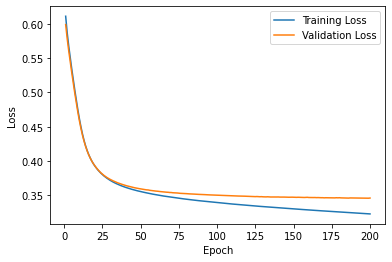

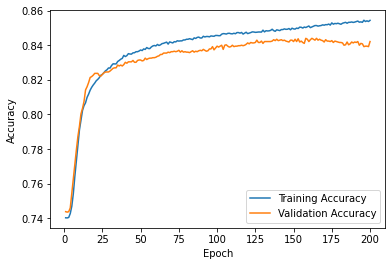

In [32]:
# Plot training loss and validation loss over epochs
# YOUR CODE HERE
print(history.history.keys())

plt.plot(range(1, num_epochs + 1), history.history['loss'], label='Training Loss')
plt.plot(range(1, num_epochs + 1), history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Plot training accuracy and validation accuracy over epochs
# YOUR CODE HERE
plt.plot(range(1, num_epochs + 1), history.history['accuracy'], label='Training Accuracy')
plt.plot(range(1, num_epochs + 1), history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Step 7: Evaluate the Model's Performance on the Test Set

<b>Task:</b> Use your neural network to generate predictions on the test set and evaluate its performance using accuracy and F1 score. Use `nn_model.predict()` to generate predictions. Since `nn_model.predict()` returns probabilities, apply a threshold of 0.5 to convert probabilities into binary class predictions before computing your metrics. Save your accuracy and F1 score results to clearly named variables so you can compare them to the results from your previous model. Print the results.

In [33]:
# Generate predictions from your neural network using your scaled test data
# nn_model.predict() returns probabilities — apply a threshold of 0.5 to get class labels

# YOUR CODE HERE
y_pred_probs = nn_model.predict(X_test_scaled)

y_pred_nn = (y_pred_probs >= 0.5).astype(int)

In [34]:
# Compute accuracy and F1 score for the neural network and print the results

# YOUR CODE HERE
nn_accuracy = accuracy_score(y_test, y_pred_nn)
nn_f1 = f1_score(y_test, y_pred_nn)

print("Accuracy:", nn_accuracy)
print("F1 Score:", nn_f1)

Accuracy: 0.8472102076124568
F1 Score: 0.6680761099365751


#### Neural Network Reflection:

<b>Task:</b> In the markdown cell below, answer the following questions:

1. Walk through the architecture decisions you made: number of layers, number of units, activation functions, learning rate, and number of epochs. Why did you make each of those choices?
2. What did your training curves tell you? Did you see any signs of overfitting or underfitting?
3. How did your neural network perform on the test set? Report your accuracy and F1 score here and note whether the result surprised you given what your training curves showed.

I used a neural network with three hidden layers containing 64, 32, and 16 units. I chose this structure because the dataset contains many features, and multiple layers allow the model to learn more complex patterns. I used the ReLU activation function for the hidden layers because it helps the network learn non-linear relationships efficiently. For the output layer, I used a sigmoid activation function because this is a binary classification problem predicting whether a listing is low or high price. I used an SGD optimizer with a learning rate of 0.001 because it provided stable training and allowed the model to gradually improve. I trained the model for 200 epochs because the model continued improving after 100 epochs, with validation performance remaining stable.

The training curves show that the model learned effectively because the training loss decreased and training accuracy increased over time. The validation accuracy remained around 84–85%, while the validation loss slightly decreased and then leveled off. There are some small signs of overfitting because training accuracy continued increasing while validation accuracy stopped improving significantly, but the difference between training and validation performance was small. Overall, the model did not show major overfitting or underfitting and was able to generalize well to unseen data.

The neural network achieved a test accuracy of 0.85 and an F1 score of 0.67. These results were expected based on the training curves because the validation accuracy stayed consistent around 84–85%, suggesting the model would perform similarly on unseen test data. The test performance was not surprising because the small gap between training and validation accuracy indicated that the model was not heavily overfitting and could generalize well.

## Part 7: Compare Your Models and Reflect

You have now applied two different approaches to the same problem. In this final section, you will put those results side by side and reflect on what you learned.

###  Results Summary

<b>Task:</b> In the code cell below, create a summary table using a Pandas DataFrame that displays each evaluation metric for both models side by side. Use the variables you created for the accuracy and F1 score metrics. The table should make it easy to compare performance at a glance across every metric you computed.

In [35]:
# Build a side-by-side comparison of your two models using the metric variables
# you created. For example:

# results = pd.DataFrame({
#     'Metric': ['Accuracy', 'F1 Score'],
#     'KNN Model': [knn_accuracy, knn_f1],
#     'Neural Network': [nn_accuracy, nn_f1]
# })
# print(results.to_string(index=False))

# YOUR CODE HERE

results = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 Score'],
    'Decision Tree Model': [dt_accuracy, dt_f1],
    'Neural Network': [nn_accuracy, nn_f1]
})
print(results.to_string(index=False))


   Metric  Decision Tree Model  Neural Network
 Accuracy             0.825260        0.847210
 F1 Score             0.594378        0.668076


### Comparative Analysis

<b>Task:</b> In the markdown cell below, write a comparative analysis that addresses the following. 

1. **Performance comparison.** How did the two models perform relative to each other? Which metrics improved, which stayed the same, and which got worse?

2. **Was the added complexity worth it?** Neural networks are more complex to build, tune, and interpret. Given the performance difference you observed, do you think the neural network justified that added complexity for this problem?

3. **Recommendation.** If you were presenting this work to your company and their client as described in the business brief, which model would you recommend deploying and why? Consider not just performance but also interpretability, training time, and what the costs of different types of errors look like for that specific client.

4. **What you would do next.** If you had more time, what would you try to improve your results? This could include trying different architectures, additional preprocessing steps, different features, or techniques to address class imbalance. Be specific.

The Neural Network performed better than the Decision Tree for both the accuracy and F1 score. The Neural Network achieved an accuracy of approximately 84.9% compared to the Decision Tree's 82.5%, showing that it was slightly better at making correct overall predictions. The F1 score also improved from 0.595 with the Decision Tree to 0.675 with the Neural Network, indicating that the Neural Network was better at balancing precision and recall when identifying high-priced listings. Since the F1 score improved more significantly than accuracy, the Neural Network appears to have been better at correctly identifying the high-priced class.

The Neural Network's added complexity was somewhat justified because it improved both accuracy and F1 score compared to the Decision Tree. However, the improvement was relatively small, especially for accuracy, which only increased by about 2%. Since Neural Networks require more time to train, more tuning, and are harder to interpret, the performance improvement may not always justify the additional complexity for this problem. The decision depends on whether the client values improved prediction performance over simplicity and interpretability.

For this business problem, I would recommend deploying the Neural Network model because it achieved the best overall performance and was better at identifying high-priced Airbnb listings based on its higher F1 score. Since the client wants to identify premium portfolio opportunities, reducing missed high-priced listings is important. However, I would also consider the Decision Tree as a strong alternative because it is easier to interpret and explain to stakeholders. If the client values transparency and understanding why a listing is classified as high-priced, the Decision Tree may be preferable despite slightly lower performance.

If I had more time, I would try additional methods to improve the model. I would experiment with different Neural Network architectures by changing the number of layers, units, activation functions, and training parameters. I would also explore additional feature engineering, such as creating features based on price-related factors, review trends, or host characteristics. 

---
## AI Use Attestation

Reflect honestly on how you used AI tools during this capstone. You are expected to have used AI somewhere in your workflow, and your reflection on that use is what will be evaluated: How clearly you describe your choices, how you verified your work, and what you learned from the process. If you chose not to use AI, explain why. Answer each question in the markdown cell below.

1. Where and at what stages of this capstone did you use AI tools, for example, Claude during brainstorming, coding, or debugging? If you chose not to use AI, explain why.
2. Identify one part of the capstone that required the most effort or thought. What made it challenging, and how did you work through it, with AI or without AI? If you used AI at this point, feel free to share a prompt that worked well or one that did not land the way you expected.
3. How did you verify that your work was correct? What did you look for to catch a mistake, whether it came from AI output or your own reasoning?
4. What is one thing you would do differently next time, either in how you approached the capstone or in how you used AI during it?

I used ChatGPT throughout the earlier stages to help understand the business problem, the possible ethical concerns, and the affected audiences as a result of this model. I did this to get a fuller grasp of the problem and ensure that I wasn't disregarding potential issues that may come along the ML model building process, and to better understand the data I was working with.

I spent the most time cleaning the data because I didn't want to exclude important pieces of information, and I also didn't want to include data that may unnecessarily increase the cost and complexity of the model. 
- Example Prompt: what are the possible biases or ethical concerns might be present in the airbnb dataset given this context? Trove Analytics' new client is a hospitality investment group that acquires and manages short-term rental properties across New York City. The group currently categorizes listings manually, using a combination of neighborhood reputation, room type, and host reviews to decide whether a listing belongs in their premium portfolio. This approach is slow, subjective, and increasingly impractical as the portfolio grows. The client wants to automate the classification of listings into pricing tiers. Specifically, they want a model that can examine a listing's features — such as location, room type, host characteristics, and review metrics — and predict whether it is high-priced. This would allow the team to quickly identify premium acquisition targets and prioritize listings for marketing investment Trove Analytics' goal is to build a binary classification model that predicts whether an Airbnb listing is high-priced. The model should learn from listing features in the NYC Airbnb dataset and produce reliable predictions for listings the team has not yet evaluated manually. A well-performing model could save the client dozens of hours per month in manual review and reduce inconsistency in how listings are categorized

I verified that my work was correct by reading over the explanation provided by the AI tool and if it aligned with the concepts already gone over in the ML course thus far. Sometimes the AI tool would offer solutions outside the scope of the course, or deviate from the task given so I found a lot of success after giving the AI tool redirection.

One thing I would do differently is spending more time understanding the code already provided by the assignment, because after skimming those lines of code I faced trouble debugging later code since I didn't understand the inputs some code desired. For example, I had to convert the label data into integers because before the loss value was not provided and had the output nan.  